# 07 - Bulk Composition Comparison with Sulfur

This notebook compares the modeled final planet compositions after the first **100 Myr** of evolution with bulk Earth and Mars reference compositions.

The sulfur comparison uses only metal-phase sulfur (`S_met`). The Earth and Mars core sulfur abundances are 1.8 wt% and 6.6 wt%, respectively; they are converted to the same molar `S_met/MgO` scale as the modeled planets before Earth normalization. `S_sil` and total `S` remain in the data table for sulfur-closure auditing, but they are not plotted.

> **Prerequisites:** Run the sulfur workflow notebooks `01` → `06` first.  
> **Inputs:** `Tables/06_differentiation_S.xlsx`, `Tables/04_planet_order_S.csv` (Planet labels ordered by final semi-major axis)  
> **Output:** `Tables/07_bulk_comparison_S.csv`

**CMF interpretation:** The plotted CMF divides modeled core mass by modeled core plus modeled mantle mass. Since the fate of unmodeled mass is unknown, it is a conditional modeled-component CMF rather than a full-body CMF. The exported lower/upper full-body CMF bounds assign all unmodeled mass outside/inside the core, respectively.


In [1]:
# Comparison reference values from E_00_CMF.ipynb; document as references, not fit targets.
PROJECT_ROOT = None
WORKFLOW_DIR = None
DIFFERENTIATION_FILE = None
ORDER_FILE = None
OUTPUT_FILE = None
PLOT_DEFAULT_YLIMS = {'Mass': (0.0, 1.15), 'Mg#': (0.68, 1.00), 'CMF': (0.15, 0.38)}
FIGURE_SIZE_MM = (183, 148) # Nature double-column width, <170 mm height
SAVE_FIGURES = False           # Publication artwork export is opt-in
METRIC_REFERENCE = {
    'Mass': {'Earth': 1.0000, 'Mars': 0.1074},
    'Mg#': {'Earth': 0.890, 'Mars': 0.775},
    'CMF': {'Earth': 0.320, 'Mars': 0.200},
}
METRIC_REFERENCE_RANGE = {
    'Mass': {'Earth': None, 'Mars': None},
    'Mg#': {'Earth': (0.801, 0.979), 'Mars': (0.698, 0.853)},
    'CMF': {'Earth': (0.288, 0.352), 'Mars': (0.180, 0.220)},
}


In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd

working_dir = Path.cwd()
project_root = (Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT is not None
                else next((p for p in (working_dir, *working_dir.parents)
                           if (p / "src" / "accrediff").is_dir()), None))
if project_root is None:
    raise RuntimeError("Could not locate the AccreDiff repository root.")
workflow_dir = (Path(WORKFLOW_DIR).expanduser().resolve() if WORKFLOW_DIR is not None
                else project_root / 'kong_2027_backup' / 'work_flow_S')

# Respect WORKFLOW_DIR for isolated batch or manual runs.
sys.path.insert(0, str(project_root / 'src'))
import accrediff as ad


plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'axes.linewidth': 1,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': False,
    'ytick.right': False,
    'figure.dpi': 150,
})

COLORS = {'Earth': '#1f77b4', 'Mars': '#d62728'}
print(f'Project root: {project_root}')
print('Setup complete.')


Project root: /Users/kong/Research/code_zju/AccreDiff
Setup complete.


## 1. Load and validate the sulfur differentiation histories

Each worksheet is one final planet's collision history during the first 100 Myr. `Planet 1` is the innermost final planet, as recorded by notebook 04. The last row is the composition retained at the end of that evolution window; the final collision itself does not have to occur exactly at 100 Myr.


In [3]:
diff_file = Path(DIFFERENTIATION_FILE) if DIFFERENTIATION_FILE is not None else workflow_dir / 'Tables' / '06_differentiation_S.xlsx'
if not diff_file.is_file():
    raise FileNotFoundError(f'Required sulfur differentiation output not found: {diff_file}')

df_dict = pd.read_excel(diff_file, sheet_name=None)
if not df_dict:
    raise ValueError(f'No planet worksheets found in {diff_file}.')

order_file = Path(ORDER_FILE) if ORDER_FILE is not None else workflow_dir / 'Tables' / '04_planet_order_S.csv'
if not order_file.is_file():
    raise FileNotFoundError(
        f'Planet orbital order not found: {order_file}. Run notebook 04 first.'
    )
planet_order = pd.read_csv(order_file)
required_order_columns = {'planet', 'final_particle_id', 'a_final_au', 'm_e_final'}
missing_order = required_order_columns - set(planet_order.columns)
if missing_order:
    raise ValueError(f'Planet order table lacks: {sorted(missing_order)}')
if planet_order['planet'].tolist() != list(df_dict):
    raise ValueError(
        'Differentiation sheets do not match the current orbital ordering. '
        'Rerun notebooks 05 and 06 after notebook 04.'
    )
if not np.isfinite(planet_order[['a_final_au', 'm_e_final']].to_numpy(dtype=float)).all():
    raise ValueError('Planet order table has non-finite orbital or mass values.')
if (planet_order['a_final_au'] <= 0.0).any() or not planet_order['a_final_au'].is_monotonic_increasing:
    raise ValueError('Planet order must have positive, increasing final semi-major axes.')

composition_items = [
    'MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2', 'S_sil',
    'Fe', 'Ni', 'Si', 'O', 'S_met', 'S',
]
required_columns = {
    'Time', 'target_id', 'm_e', *composition_items,
    'accepted', 'accepted_approximate', 'O_KD_log_residual',
}

for name, history in df_dict.items():
    if history.empty:
        raise ValueError(f'{name} contains no differentiation events.')
    missing = required_columns - set(history.columns)
    if missing:
        raise ValueError(f'{name} lacks required columns: {sorted(missing)}')
    if not history['Time'].is_monotonic_increasing:
        raise ValueError(f'{name} is not ordered by increasing time.')
    if not history['accepted'].astype(bool).all():
        raise ValueError(f'{name} contains an unaccepted differentiation event.')
    values = history[composition_items].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values < -1e-12).any():
        raise ValueError(f'{name} contains non-finite or negative composition values.')
    if (history['MgO'] <= 0.0).any():
        raise ValueError(f'{name} contains a non-positive MgO inventory.')
    if not np.allclose(
        history['S'], history['S_sil'] + history['S_met'],
        rtol=0.0, atol=1e-10,
    ):
        raise ValueError(f'{name} fails S = S_sil + S_met closure.')
    if (history['S_met'] > history['S'] + 1e-12).any():
        raise ValueError(f'{name} contains S_met greater than total S.')

print(f'Loaded: {diff_file}')
print(f'Planet sheets: {list(df_dict)}')


Loaded: /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/06_differentiation_S.xlsx
Planet sheets: ['planets_1', 'planets_2', 'planets_3', 'planets_4', 'planets_5', 'planets_6']


## 2. Extract the final 100 Myr planet states and solver-history provenance

The final composition carries the accumulated effect of every earlier event. Solver-history statistics therefore accompany each planet even when its last event has an exact solution.


In [4]:
final_rows = []
history_audits = []

for sheet_name, history in df_dict.items():
    final_row = history.iloc[-1].copy()
    final_row['planet'] = sheet_name
    order_row = planet_order.iloc[len(final_rows)]
    if int(final_row['target_id']) != int(order_row['final_particle_id']):
        raise ValueError(
            f'{sheet_name} final particle ID differs from the orbital order table. '
            'Rerun notebooks 05 and 06 after notebook 04.'
        )
    if not np.isclose(float(final_row['m_e']), float(order_row['m_e_final']), rtol=1e-4, atol=1e-6):
        raise ValueError(f'{sheet_name} final mass differs from the orbital order table.')
    final_row['a_final_au'] = float(order_row['a_final_au'])
    final_rows.append(final_row)

    approximate = history['accepted_approximate'].astype(bool)
    oxygen_residual = pd.to_numeric(history['O_KD_log_residual'], errors='coerce').abs()
    history_audits.append({
        'planet': sheet_name,
        'event_count': len(history),
        'approximate_event_count': int(approximate.sum()),
        'approximate_fraction': float(approximate.mean()),
        'max_abs_O_KD_log_residual': float(oxygen_residual.max()),
        'contains_approximate_history': bool(approximate.any()),
    })

df_planets = pd.DataFrame(final_rows).reset_index(drop=True)
df_history_audit = pd.DataFrame(history_audits)

if not np.allclose(
    df_planets['S'], df_planets['S_sil'] + df_planets['S_met'],
    rtol=0.0, atol=1e-10,
):
    raise RuntimeError('Final planet sulfur phase closure failed.')

print(f'Final planets extracted: {len(df_planets)}')
display(df_planets[['planet', 'a_final_au', 'Time', 'target_id', 'm_e', 'S', 'S_sil', 'S_met']])
display(df_history_audit)


Final planets extracted: 6


,planet,a_final_au,Time,target_id,m_e,S,S_sil,S_met
0,planets_1,0.713129,174.488983,316,0.586985,0.069532,0.000423,0.069109
1,planets_2,0.921611,169.462080,165,0.351987,0.072774,0.000169,0.072604
2,planets_3,1.216084,173.770604,678,0.711395,0.077994,0.000368,0.077626
3,planets_4,1.590414,165.347857,1948,0.146963,0.100029,0.002578,0.097450
4,planets_5,1.953605,146.062388,724,0.038837,0.100231,0.003148,0.097083
5,planets_6,2.387254,171.473108,1103,0.038831,0.086502,0.002019,0.084483


,planet,event_count,approximate_event_count,approximate_fraction,max_abs_O_KD_log_residual,contains_approximate_history
0,planets_1,127,0,0.0,7.973059e-12,False
1,planets_2,55,0,0.0,9.113859e-13,False
2,planets_3,119,0,0.0,8.997850e-12,False
3,planets_4,45,0,0.0,2.462121e-12,False
4,planets_5,19,0,0.0,5.761857e-14,False
5,planets_6,12,0,0.0,3.153351e-14,False


## 3. Normalize modeled compositions to MgO

Only the explicitly listed composition columns are divided by MgO. Diagnostic fields are left unchanged, and any non-finite normalized result is treated as an error.


In [5]:
mantle_items = ['MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2']
core_items = ['Fe', 'Ni', 'Si', 'O', 'S_met']
normalization_items = mantle_items + core_items
comparison_items = ['Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2', 'Fe', 'Ni', 'Si', 'O', 'S_met']
plot_labels = [r'Al$_2$O$_3$', 'CaO', 'FeO', 'NiO', r'SiO$_2$', 'Fe', 'Ni', 'Si', 'O', 'S']

df_planets_Mg = df_planets.copy()
df_planets_Mg[normalization_items] = df_planets[normalization_items].div(
    df_planets['MgO'], axis=0
)
if not np.isfinite(df_planets_Mg[normalization_items].to_numpy(dtype=float)).all():
    raise RuntimeError('MgO normalization produced a non-finite composition.')

print('MgO-normalized modeled compositions:')
display(df_planets_Mg[['planet'] + comparison_items])


MgO-normalized modeled compositions:


,planet,Al2O3,CaO,FeO,NiO,SiO2,Fe,Ni,Si,O,S_met
0,planets_1,0.045559,0.066442,0.099511,0.004306,0.864935,0.703454,0.039867,0.034322,0.016025,0.114732
1,planets_2,0.044186,0.064413,0.119405,0.004198,0.894253,0.681041,0.039900,0.037585,0.017450,0.121144
2,planets_3,0.043141,0.062884,0.121546,0.006111,0.923320,0.675455,0.037825,0.032064,0.022794,0.130266
3,planets_4,0.040441,0.059116,0.200384,0.002963,0.999557,0.568015,0.039265,0.006361,0.007705,0.165764
4,planets_5,0.043702,0.063902,0.201450,0.003115,0.907255,0.578842,0.039646,0.021894,0.008275,0.164871
5,planets_6,0.045361,0.066551,0.174558,0.002284,0.879964,0.583573,0.038985,0.001673,0.004785,0.139486


## 4. Build Earth and Mars references, including core sulfur

The reference sulfur value is a bulk-planet metal-phase inventory normalized to mantle MgO:

\[
(S_{met}/MgO)_p =
\frac{w_{S,core} f_{core}/M_S}
     {w_{MgO,mantle} f_{mantle}/M_{MgO}}.
\]

The adopted core sulfur concentrations are 1.8 wt% for Earth and 6.6 wt% for Mars. They are not inserted directly into the plot as wt%; the calculation below converts them to the same molar scale as the model.


In [6]:
molar_mass_MgO = ad.constants.Elements['Mg'] + ad.constants.Elements['O']
molar_mass_S = ad.constants.Elements['S']

def core_sulfur_per_mantle_mgo(mantle, core):
    sulfur_moles = core['S'] * core['core'] / molar_mass_S
    mgo_moles = mantle['MgO'] * mantle['mantle'] / molar_mass_MgO
    value = sulfur_moles / mgo_moles
    if not np.isfinite(value) or value <= 0.0:
        raise ValueError('The S_met/MgO reference must be finite and positive.')
    return value

calculated_s_refs = {
    'Earth': core_sulfur_per_mantle_mgo(ad.constants.Earth_mantle, ad.constants.Earth_core),
    'Mars': core_sulfur_per_mantle_mgo(ad.constants.Mars_mantle, ad.constants.Mars_core),
}

Earth_bulk_mg = dict(ad.constants.Earth_bulk_mg)
Mars_bulk_mg = dict(ad.constants.Mars_bulk_mg)
for body, reference in [('Earth', Earth_bulk_mg), ('Mars', Mars_bulk_mg)]:
    if 'S_met' not in reference:
        raise KeyError(f'{body}_bulk_mg lacks the S_met reference.')
    if not np.isclose(reference['S_met'], calculated_s_refs[body], rtol=1e-12, atol=0.0):
        raise ValueError(f'{body} stored S_met/MgO is inconsistent with its core sulfur input.')

reference_mg = pd.DataFrame(
    [Earth_bulk_mg, Mars_bulk_mg], index=['Earth', 'Mars']
).reindex(columns=['MgO'] + comparison_items)
if reference_mg.isna().any().any() or (reference_mg <= 0.0).any().any():
    zero_allowed = (reference_mg.index == 'Mars')[:, None] & (reference_mg.columns == 'Si')[None, :]
    invalid = (~np.isfinite(reference_mg.to_numpy(dtype=float))) | (reference_mg.to_numpy(dtype=float) < 0.0)
    if (invalid & ~zero_allowed).any():
        raise ValueError('Earth/Mars reference table contains invalid values.')

print('Core sulfur inputs: Earth = 1.8 wt%, Mars = 6.6 wt%')
print('Converted S_met/MgO references:')
display(reference_mg[['S_met']])


Core sulfur inputs: Earth = 1.8 wt%, Mars = 6.6 wt%
Converted S_met/MgO references:


,S_met
Earth,0.029082
Mars,0.062452


## 5. Normalize modeled planets and Mars to Earth

`S_met` is treated consistently with the other core components: both the modeled value and the Mars reference are divided by the Earth `S_met/MgO` reference. `S_sil` and total `S` are not included in this comparison.


In [7]:
earth_base = reference_mg.loc['Earth', comparison_items]
if not np.isfinite(earth_base.to_numpy(dtype=float)).all() or (earth_base <= 0.0).any():
    raise ValueError('Earth normalization base must be finite and strictly positive.')

df_planets_Earth = df_planets_Mg[comparison_items].div(earth_base, axis=1)
df_Mars_Earth = reference_mg.loc[['Mars'], comparison_items].div(earth_base, axis=1)

if not np.isfinite(df_planets_Earth.to_numpy(dtype=float)).all():
    raise RuntimeError('Earth normalization produced non-finite modeled values.')

print('Modeled planets normalized to MgO and Earth:')
display(df_planets_Earth)
print('Mars normalized to MgO and Earth:')
display(df_Mars_Earth)


Modeled planets normalized to MgO and Earth:


,Al2O3,CaO,FeO,NiO,SiO2,Fe,Ni,Si,O,S_met
0,0.981059,0.987021,0.831842,1.206483,1.085471,0.886981,0.885583,0.465244,0.247463,3.945153
1,0.951514,0.956877,0.998144,1.176194,1.122264,0.858721,0.886325,0.509485,0.269473,4.165628
2,0.929003,0.934167,1.016039,1.711906,1.158743,0.851677,0.840232,0.434647,0.351990,4.479266
3,0.870861,0.878191,1.675072,0.830077,1.254418,0.716207,0.872212,0.086227,0.118986,5.699895
4,0.941084,0.949281,1.683984,0.872662,1.138581,0.729858,0.880668,0.296786,0.127789,5.669208
5,0.976808,0.988636,1.459186,0.639836,1.104332,0.735824,0.865983,0.022682,0.073895,4.796319


Mars normalized to MgO and Earth:


,Al2O3,CaO,FeO,NiO,SiO2,Fe,Ni,Si,O,S_met
Mars,0.98592,0.992017,2.223885,0.224361,1.235649,0.544566,0.849789,0.0,1.52273,2.14744


## 6. Bulk-composition spider diagram at 100 Myr

Squares show modeled planets and the star shows Mars. The `S` coordinate contains only metal-phase sulfur (`S_met`). Marker size scales with final planet mass; the gray band marks ±10% around the Earth reference.


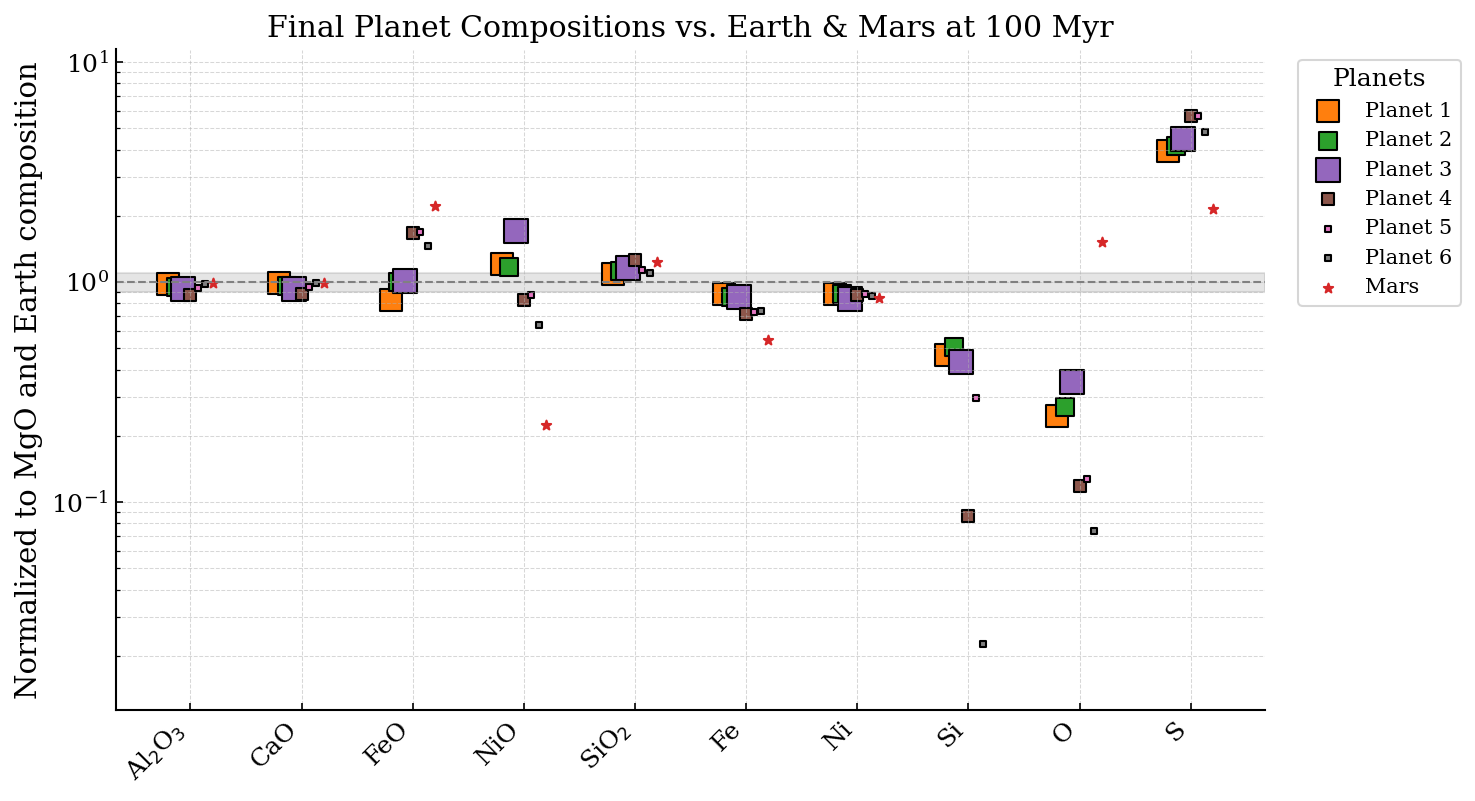

In [8]:
planet_ids = [f'Planet {i + 1}' for i in range(len(df_planets))]
cmap = plt.get_cmap('tab10')
color_idx = [i for i in range(10) if i not in (0, 3)]
colors = [cmap(color_idx[i % len(color_idx)]) for i in range(len(df_planets))]

x_idx = np.arange(len(comparison_items))
offsets = np.linspace(-0.2, 0.2, len(df_planets) + 1)
fig, ax = plt.subplots(figsize=(10, 5.5))

for i in range(len(df_planets)):
    y = df_planets_Earth.iloc[i].to_numpy(dtype=float)
    y[y <= 0.0] = np.nan
    ax.scatter(
        x_idx + offsets[i], y,
        marker='s', s=200 * df_planets['m_e'].iloc[i],
        color=colors[i], edgecolor='k', alpha=1,
        label=planet_ids[i],
    )

y_mars = df_Mars_Earth.iloc[0].to_numpy(dtype=float)
y_mars[y_mars <= 0.0] = np.nan
ax.scatter(
    x_idx + offsets[-1], y_mars,
    marker='*', s=200 * ad.constants.Mars_ME,
    color=COLORS['Mars'], alpha=1, label='Mars',
)

ax.axhline(1.0, color='gray', linestyle='--', linewidth=1)
ax.axhspan(0.9, 1.1, color='gray', alpha=0.2, zorder=0)
ax.grid(True, which='both', ls='--', lw=0.5, alpha=0.5)
ax.set_yscale('log')
positive = np.concatenate([
    df_planets_Earth.to_numpy(dtype=float).ravel(),
    df_Mars_Earth.to_numpy(dtype=float).ravel(),
])
positive = positive[np.isfinite(positive) & (positive > 0.0)]
ax.set_ylim(max(positive.min() / 2.0, 1e-4), max(positive.max() * 2.0, 2.0))
ax.set_xticks(x_idx)
ax.set_xticklabels(plot_labels, rotation=45, ha='right')
ax.set_ylabel('Normalized to MgO and Earth composition')
ax.set_title('Final Planet Compositions vs. Earth & Mars at 100 Myr')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(title='Planets', bbox_to_anchor=(1.02, 1.0), loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()


## 7. Calculate Mass, Mg#, and sulfur-inclusive CMF

The three diagnostics use the same final 100 Myr states as the bulk-composition plot. `Mg#` is the mantle molar ratio $MgO/(MgO+FeO)$. The plotted CMF is conditional on the modeled chemical components; unmodeled mass is excluded from its denominator. Separate full-body lower and upper bounds assume the unmodeled mass lies entirely outside or entirely inside the core. The core mass fraction is reconstructed from all phase components: `S_met` contributes to the core, `S_sil` contributes to the mantle, and total `S` is not added again.

Every final planet is retained as an individual object. No Earth/Mars analog classification is applied.


In [9]:
atomic_mass = ad.constants.Elements
molar_mass = {
    'MgO': atomic_mass['Mg'] + atomic_mass['O'],
    'Al2O3': 2.0 * atomic_mass['Al'] + 3.0 * atomic_mass['O'],
    'CaO': atomic_mass['Ca'] + atomic_mass['O'],
    'FeO': atomic_mass['Fe'] + atomic_mass['O'],
    'NiO': atomic_mass['Ni'] + atomic_mass['O'],
    'SiO2': atomic_mass['Si'] + 2.0 * atomic_mass['O'],
    'Fe': atomic_mass['Fe'],
    'Ni': atomic_mass['Ni'],
    'Si': atomic_mass['Si'],
    'O': atomic_mass['O'],
    'S': atomic_mass['S'],
}

silicate_mass_terms = ['MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2']
metal_mass_terms = ['Fe', 'Ni', 'Si', 'O']

mantle_mass = sum(
    df_planets[item] * molar_mass[item] for item in silicate_mass_terms
) + df_planets['S_sil'] * molar_mass['S']
core_mass = sum(
    df_planets[item] * molar_mass[item] for item in metal_mass_terms
) + df_planets['S_met'] * molar_mass['S']
total_reconstructed_mass = mantle_mass + core_mass
# Mol per 100 g whole body times g/mol gives grams per 100 g.
# Missing species are not assigned to core or mantle.
tracked_mass_fraction_reconstructed = total_reconstructed_mass / 100.0
if not np.allclose(
    tracked_mass_fraction_reconstructed.to_numpy(dtype=float)
    + df_planets['untracked_mass_fraction'].to_numpy(dtype=float),
    1.0, rtol=0.0, atol=1e-7,
):
    raise RuntimeError('Final planet modeled and unmodeled masses do not close.')

mg_denominator = df_planets['MgO'] + df_planets['FeO']
if (mg_denominator <= 0.0).any():
    raise ValueError('Mg# requires MgO + FeO > 0.')

metrics = pd.DataFrame({
    'planet': df_planets['planet'],
    'Mass': df_planets['m_e'].to_numpy(dtype=float),
    'Mg_number': (df_planets['MgO'] / mg_denominator).to_numpy(dtype=float),
    'mantle_mass_reconstructed': mantle_mass.to_numpy(dtype=float),
    'core_mass_reconstructed': core_mass.to_numpy(dtype=float),
    # Conditional CMF within the modeled chemical inventory only.
    'CMF': (core_mass / total_reconstructed_mass).to_numpy(dtype=float),
    'tracked_mass_fraction_reconstructed': tracked_mass_fraction_reconstructed.to_numpy(dtype=float),
    # If the missing material's phase is unknown, these bound the
    # full-body core mass fraction without assigning it to a phase.
    'CMF_full_lower_bound': (core_mass / 100.0).to_numpy(dtype=float),
    'CMF_full_upper_bound': (
        core_mass / 100.0 + df_planets['untracked_mass_fraction']
    ).to_numpy(dtype=float),
})

numeric_metric_columns = [
    'Mass', 'Mg_number', 'mantle_mass_reconstructed',
    'core_mass_reconstructed', 'CMF', 'tracked_mass_fraction_reconstructed',
    'CMF_full_lower_bound', 'CMF_full_upper_bound',
]
if not np.isfinite(metrics[numeric_metric_columns].to_numpy(dtype=float)).all():
    raise RuntimeError('Mass, Mg#, or CMF calculation produced a non-finite value.')
if (metrics[['mantle_mass_reconstructed', 'core_mass_reconstructed']] <= 0.0).any().any():
    raise RuntimeError('Reconstructed mantle and core masses must be positive.')
if not metrics['Mg_number'].between(0.0, 1.0, inclusive='both').all():
    raise RuntimeError('Mg# lies outside [0, 1].')
if not metrics['CMF'].between(0.0, 1.0, inclusive='both').all():
    raise RuntimeError('CMF lies outside [0, 1].')
if not (
    metrics['CMF_full_lower_bound'].between(0.0, 1.0, inclusive='both').all()
    and metrics['CMF_full_upper_bound'].between(0.0, 1.0, inclusive='both').all()
    and (metrics['CMF_full_lower_bound'] <= metrics['CMF']).all()
    and (metrics['CMF'] <= metrics['CMF_full_upper_bound']).all()
):
    raise RuntimeError('Full-body CMF bounds are inconsistent with modeled CMF.')

metric_reference = METRIC_REFERENCE
metric_reference_range = METRIC_REFERENCE_RANGE

print('Final-planet diagnostics:')
display(metrics)
print('E_00_CMF Earth/Mars reference values:')
display(pd.DataFrame(metric_reference).T)


Final-planet diagnostics:


,planet,Mass,Mg_number,mantle_mass_reconstructed,core_mass_reconstructed,CMF,tracked_mass_fraction_reconstructed,CMF_full_lower_bound,CMF_full_upper_bound
0,planets_1,0.586985,0.909495,65.135802,28.023011,0.300809,0.931588,0.280230,0.348642
1,planets_2,0.351987,0.893332,66.555589,27.324921,0.291061,0.938805,0.273249,0.334444
2,planets_3,0.711395,0.891627,67.285383,27.043457,0.286693,0.943288,0.270435,0.327146
3,planets_4,0.146963,0.833067,72.049753,23.304824,0.244402,0.953546,0.233048,0.279502
4,planets_5,0.038837,0.832328,69.325146,23.957361,0.256826,0.932825,0.239574,0.306749
5,planets_6,0.038831,0.851384,69.258983,23.907914,0.256614,0.931669,0.239079,0.307410


E_00_CMF Earth/Mars reference values:


,Earth,Mars
Mass,1.00,0.1074
Mg#,0.89,0.7750
CMF,0.32,0.2000


## 8. Planet-by-planet Mass–Mg#–CMF comparison at 100 Myr

All final planets share the actual final semi-major axis `a` (au) as the x-coordinate. The horizontal distance therefore shows orbital spacing directly; colours and the compact key identify the Planet numbers. Each panel expands its physical y-axis as needed to include the current planets and both Earth and Mars references; Mg# and CMF remain within their physical [0, 1] domain. The Mg# and CMF shaded regions reproduce the comparison ranges in `E_00_CMF.ipynb`; they are comparison ranges rather than observational uncertainty estimates.

The layout follows Nature artwork guidance for a double-column figure: 183 mm width, Helvetica lettering, 5–7 pt general text, 8 pt bold panel labels, 0.25–1 pt strokes, and compact whitespace. Optional PDF/SVG/PNG export lines are kept commented out by default. The explanatory title belongs in the manuscript figure legend rather than inside the artwork.


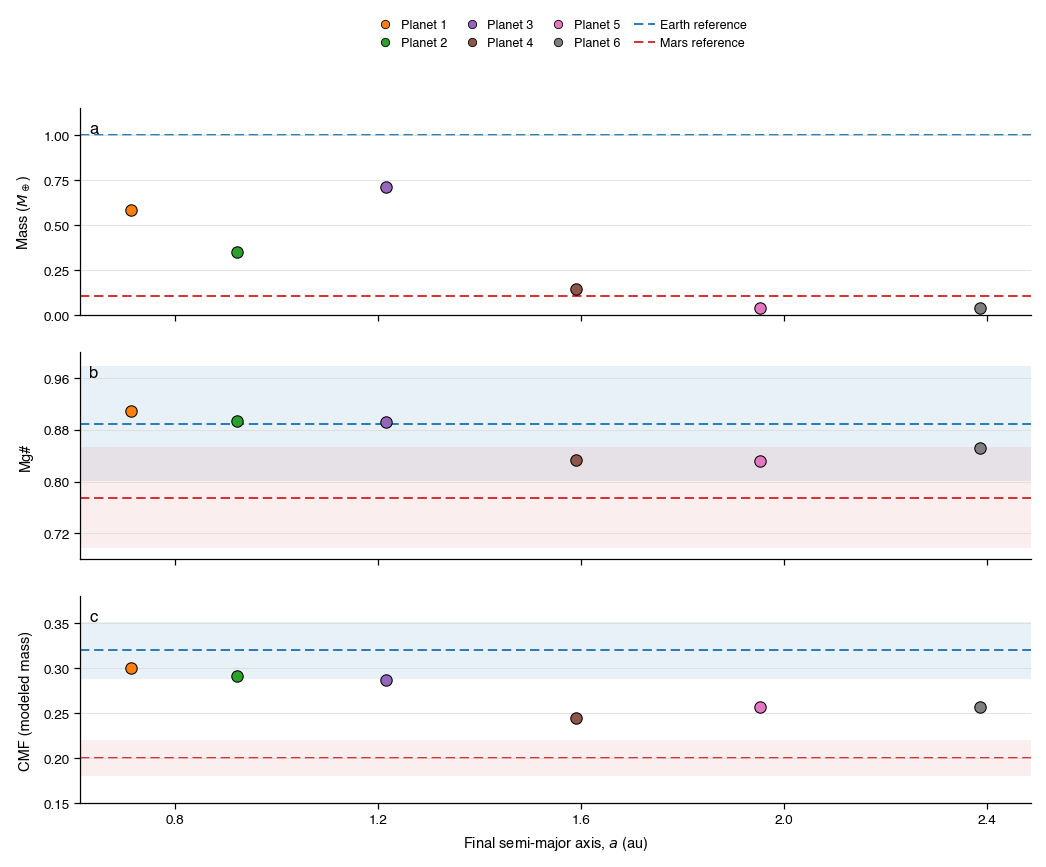

In [10]:
metric_specs = [
    {
        'panel': 'a', 'name': 'Mass', 'column': 'Mass',
        'ylabel': r'Mass ($M_\oplus$)', 'default_ylim': PLOT_DEFAULT_YLIMS['Mass'],
    },
    {
        'panel': 'b', 'name': 'Mg#', 'column': 'Mg_number',
        'ylabel': 'Mg#', 'default_ylim': PLOT_DEFAULT_YLIMS['Mg#'],
    },
    {
        'panel': 'c', 'name': 'CMF', 'column': 'CMF',
        'ylabel': 'CMF (modeled mass)', 'default_ylim': PLOT_DEFAULT_YLIMS['CMF'],
    },
]

from matplotlib.ticker import MaxNLocator

x = df_planets['a_final_au'].to_numpy(dtype=float)
planet_labels = [f'Planet {i + 1}' for i in range(len(metrics))]
if not np.isfinite(x).all() or (x <= 0.0).any() or np.any(np.diff(x) <= 0.0):
    raise ValueError('Final semi-major axes must be positive and strictly increasing.')

# Nature double-column artwork: 183 mm wide and below the 170 mm maximum height.
mm_to_inch = 1.0 / 25.4
with plt.rc_context({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 6.5,
    'axes.labelsize': 7.0,
    'xtick.labelsize': 6.5,
    'ytick.labelsize': 6.5,
    'axes.linewidth': 0.6,
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    'xtick.major.size': 3.0,
    'ytick.major.size': 3.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
}):
    fig, axes = plt.subplots(
        3, 1,
        figsize=(FIGURE_SIZE_MM[0] * mm_to_inch, FIGURE_SIZE_MM[1] * mm_to_inch),
        sharex=True,
    )

    for ax, spec in zip(axes, metric_specs):
        metric_name = spec['name']
        values = metrics[spec['column']].to_numpy(dtype=float)
        if not np.isfinite(values).all():
            raise ValueError(f'{metric_name} contains non-finite values.')
        if metric_name == 'Mass' and (values <= 0.0).any():
            raise ValueError('Planet mass must be positive.')
        if metric_name != 'Mass' and ((values < 0.0) | (values > 1.0)).any():
            raise ValueError(f'{metric_name} must lie within the physical range [0, 1].')

        earth_range = metric_reference_range[metric_name]['Earth']
        mars_range = metric_reference_range[metric_name]['Mars']
        # Expand the former display range when a new N-body run requires it.
        # Include reference values and shaded intervals so none are clipped.
        shown = list(values) + list(metric_reference[metric_name].values())
        for reference_range in (earth_range, mars_range):
            if reference_range is not None:
                shown.extend(reference_range)
        data_min, data_max = min(shown), max(shown)
        padding = 0.05 * (data_max - data_min)
        default_min, default_max = spec['default_ylim']
        ymin = min(default_min, data_min - padding)
        ymax = max(default_max, data_max + padding)
        if metric_name == 'Mass':
            ymin = max(0.0, ymin)
        else:
            ymin, ymax = max(0.0, ymin), min(1.0, ymax)
        if earth_range is not None:
            ax.axhspan(*earth_range, color=COLORS['Earth'], alpha=0.10, linewidth=0, zorder=0)
        if mars_range is not None:
            ax.axhspan(*mars_range, color=COLORS['Mars'], alpha=0.08, linewidth=0, zorder=0)

        ax.axhline(
            metric_reference[metric_name]['Earth'], color=COLORS['Earth'],
            linestyle=(0, (5, 2.5)), linewidth=0.9, zorder=1,
        )
        ax.axhline(
            metric_reference[metric_name]['Mars'], color=COLORS['Mars'],
            linestyle=(0, (5, 2.5)), linewidth=0.9, zorder=1,
        )

        for i, value in enumerate(values):
            ax.scatter(
                x[i], value, s=30, color=colors[i], edgecolor='black',
                linewidth=0.5, zorder=3,
            )

        ax.set_ylabel(spec['ylabel'], labelpad=5)
        ax.set_ylim(ymin, ymax)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=3))
        axis_pad = max(0.05, 0.06 * (x[-1] - x[0]))
        ax.set_xlim(max(0.0, x[0] - axis_pad), x[-1] + axis_pad)
        ax.grid(axis='y', color='#d9d9d9', linewidth=0.35, zorder=0)
        ax.tick_params(direction='out', top=False, right=False, pad=2)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(0.6)
        ax.spines['bottom'].set_linewidth(0.6)
        ax.text(
            0.01, 0.94, spec['panel'], transform=ax.transAxes,
            ha='left', va='top', fontsize=8, fontweight='bold',
        )

    axes[-1].xaxis.set_major_locator(MaxNLocator(nbins=6, min_n_ticks=4))
    axes[-1].set_xlabel('Final semi-major axis, $a$ (au)', labelpad=4)

    # A compact key identifies the two reference systems; shaded ranges are
    # defined in the figure legend/caption to keep the artwork uncluttered.
    planet_handles = [
        Line2D([0], [0], marker='o', linestyle='none', color=colors[i],
               markeredgecolor='black', markeredgewidth=0.4, markersize=4,
               label=planet_labels[i])
        for i in range(len(metrics))
    ]
    reference_handles = [
        Line2D([0], [0], color=COLORS['Earth'], linestyle=(0, (5, 2.5)),
               linewidth=0.9, label='Earth reference'),
        Line2D([0], [0], color=COLORS['Mars'], linestyle=(0, (5, 2.5)),
               linewidth=0.9, label='Mars reference'),
    ]
    fig.legend(
        handles=planet_handles + reference_handles, loc='upper center', ncol=4,
        bbox_to_anchor=(0.55, 1.005), frameon=False,
        handlelength=1.7, columnspacing=1.1, handletextpad=0.4,
        fontsize=6.0,
    )
    fig.align_ylabels(axes)
    fig.subplots_adjust(left=0.105, right=0.985, bottom=0.095, top=0.89, hspace=0.18)

    if SAVE_FIGURES:
        figure_dir = workflow_dir / 'Figures'
        figure_dir.mkdir(parents=True, exist_ok=True)
        figure_base = figure_dir / '07_mass_mg_cmf_nature'
        fig.savefig(figure_base.with_suffix('.pdf'))
        fig.savefig(figure_base.with_suffix('.svg'))
        fig.savefig(figure_base.with_suffix('.png'), dpi=600)
    plt.show()


## 9. Export the final comparison table

The CSV retains the original final compositions, MgO- and Earth-normalized comparison columns, solver-history provenance, the final orbital semi-major axis, and the Mass–Mg#–CMF diagnostics shown above.


In [11]:
save_dir = workflow_dir / 'Tables'
save_dir.mkdir(parents=True, exist_ok=True)
save_file = Path(OUTPUT_FILE) if OUTPUT_FILE is not None else save_dir / '07_bulk_comparison_S.csv'

df_export = (
    df_planets
    .merge(df_history_audit, on='planet', how='left', validate='one_to_one')
    .merge(metrics, on='planet', how='left', validate='one_to_one')
)
for item in normalization_items:
    df_export[f'{item}_per_MgO'] = df_planets_Mg[item].to_numpy()
for item in comparison_items:
    df_export[f'{item}_Earth_norm'] = df_planets_Earth[item].to_numpy()

df_export.to_csv(save_file, index=False)
exported = pd.read_csv(save_file)
if len(exported) != len(df_export):
    raise AssertionError('Exported row count changed.')
if not np.allclose(
    exported['S'], exported['S_sil'] + exported['S_met'],
    rtol=0.0, atol=1e-10,
):
    raise AssertionError('Exported sulfur phase closure failed.')
if not exported['Mg_number'].between(0.0, 1.0, inclusive='both').all():
    raise AssertionError('Exported Mg# lies outside [0, 1].')
if not np.allclose(
    exported['tracked_mass_fraction'] + exported['untracked_mass_fraction'],
    1.0, rtol=0.0, atol=1e-7,
):
    raise AssertionError('Exported complete-body mass coverage failed.')
if not exported['CMF'].between(0.0, 1.0, inclusive='both').all():
    raise AssertionError('Exported CMF lies outside [0, 1].')

print(f'Saved: {save_file}')
print(f'Shape: {exported.shape}')
display(exported)


Saved: /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/07_bulk_comparison_S.csv
Shape: (6, 74)


,Time,target_id,impactor_id,event,P_equil,T_equil,k_mantle,MgO,Al2O3,CaO,...,Al2O3_Earth_norm,CaO_Earth_norm,FeO_Earth_norm,NiO_Earth_norm,SiO2_Earth_norm,Fe_Earth_norm,Ni_Earth_norm,Si_Earth_norm,O_Earth_norm,S_met_Earth_norm
0,174.488983,316,2480,small,50.308290,3321.311251,NaN,0.602349,0.027442,0.040021,...,0.981059,0.987021,0.831842,1.206483,1.085471,0.886981,0.885583,0.465244,0.247463,3.945153
1,169.462080,165,2477,small,31.598790,2730.882459,NaN,0.599319,0.026482,0.038604,...,0.951514,0.956877,0.998144,1.176194,1.122264,0.858721,0.886325,0.509485,0.269473,4.165628
2,173.770604,678,2078,small,59.870625,3558.452121,NaN,0.595902,0.025708,0.037473,...,0.929003,0.934167,1.016039,1.711906,1.158743,0.851677,0.840232,0.434647,0.351990,4.479266
3,165.347857,1948,2317,partial,2.504080,2002.193660,0.240606,0.587887,0.023775,0.034754,...,0.870861,0.878191,1.675072,0.830077,1.254418,0.716207,0.872212,0.086227,0.118986,5.699895
4,146.062388,724,1216,small,3.340681,2040.474832,NaN,0.588844,0.025734,0.037628,...,0.941084,0.949281,1.683984,0.872662,1.138581,0.729858,0.880668,0.296786,0.127789,5.669208
5,171.473108,1103,2357,small,4.099077,2073.304875,NaN,0.605674,0.027474,0.040308,...,0.976808,0.988636,1.459186,0.639836,1.104332,0.735824,0.865983,0.022682,0.073895,4.796319


## 10. Summary

| Step | Operation | Output |
|---|---|---|
| 1 | Load sulfur histories and verify 04 orbital ordering | `df_dict`, `planet_order` |
| 2 | Extract final states and summarize solver provenance | `df_planets`, `df_history_audit` |
| 3 | Normalize modeled phase components to MgO | `df_planets_Mg` |
| 4 | Convert 1.8/6.6 wt% core S to Earth/Mars `S_met/MgO` references | `reference_mg` |
| 5 | Normalize modeled planets and Mars to Earth | `df_planets_Earth`, `df_Mars_Earth` |
| 6 | Plot the 100 Myr comparison; sulfur means `S_met` only | spider diagram |
| 7 | Reconstruct sulfur-inclusive mantle/core masses and calculate Mg#/CMF | `metrics` |
| 8 | Compare each planet with common Earth/Mars references in Nature-style panels | inline plot; optional export commented out |
| 9 | Export compositions, normalized values, diagnostics, and solver history | `Tables/07_bulk_comparison_S.csv` |

The sulfur workflow is now complete through the final bulk-composition comparison. Approximate-event counts are retained so that their frequency and parameter range can be studied after all N-body datasets have been processed.
